# 01 — Khám phá dữ liệu MNIST

Kiểm tra dữ liệu, phân phối nhãn và đặc điểm ảnh trước khi huấn luyện. Phân tích chi tiết chỉ dùng **60.000 ảnh train gốc**; test chỉ kiểm tra định dạng. Hình và bảng được lưu tại `results/eda/` để dùng cho report và slide.

Chạy notebook từ thư mục gốc đồ án hoặc `notebooks/`.


## 1. Import và nạp dữ liệu


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist

SEED = 42
OUTPUT = ROOT / 'results' / 'eda'
OUTPUT.mkdir(parents=True, exist_ok=True)
X_train, y_train, X_test, y_test = load_prepared_mnist()


## 2. Kiểm tra dữ liệu

`data.py` đã chia pixel cho 255 và làm phẳng ảnh; nhãn giữ dạng số nguyên, không dùng one-hot.


In [2]:
overview = pd.DataFrame([
    {'split': name, 'X_shape': str(X.shape), 'y_shape': str(y.shape),
     'X_dtype': str(X.dtype), 'y_dtype': str(y.dtype),
     'pixel_min': X.min(), 'pixel_max': X.max(), 'nonfinite': (~np.isfinite(X)).sum()}
    for name, X, y in [('Train gốc', X_train, y_train), ('Test', X_test, y_test)]
])
display(overview)
print('Nhãn train:', np.unique(y_train))
print('Nhãn test :', np.unique(y_test))
overview.to_csv(OUTPUT / 'data_overview.csv', index=False)


,split,X_shape,y_shape,X_dtype,y_dtype,pixel_min,pixel_max,nonfinite
0,Train gốc,"(60000, 784)","(60000,)",float32,uint8,0.0,1.0,0
1,Test,"(10000, 784)","(10000,)",float32,uint8,0.0,1.0,0


Nhãn train: [0 1 2 3 4 5 6 7 8 9]
Nhãn test : [0 1 2 3 4 5 6 7 8 9]


**Nhận xét:** dữ liệu cần có 60.000 ảnh train gốc và 10.000 ảnh test, mỗi ảnh 784 đặc trưng; pixel trong [0, 1], không có giá trị không hữu hạn. Các notebook mô hình sẽ chia train gốc thành 50.000 train / 10.000 validation, cùng seed và cách chia.


## 3. Phân phối nhãn


,digit,count,percentage
0,0,5923,9.87
1,1,6742,11.24
2,2,5958,9.93
3,3,6131,10.22
4,4,5842,9.74
5,5,5421,9.04
6,6,5918,9.86
7,7,6265,10.44
8,8,5851,9.75
9,9,5949,9.92


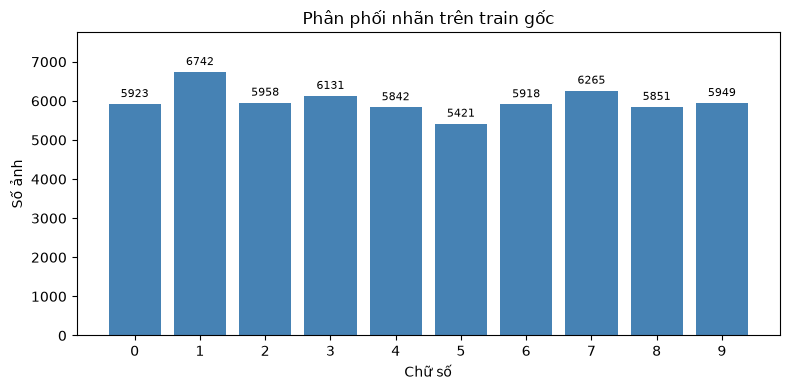

Tỷ lệ lớp: 9.04%–11.24%.


In [3]:
counts = np.bincount(y_train, minlength=10)
class_table = pd.DataFrame({'digit': np.arange(10), 'count': counts, 'percentage': counts / len(y_train) * 100})
display(class_table.round(2))
class_table.to_csv(OUTPUT / 'class_distribution.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(np.arange(10), counts, color='steelblue')
ax.bar_label(bars, padding=3, fontsize=8)
ax.set(xticks=np.arange(10), xlabel='Chữ số', ylabel='Số ảnh', title='Phân phối nhãn trên train gốc', ylim=(0, counts.max() * 1.15))
fig.tight_layout()
fig.savefig(OUTPUT / 'class_distribution.png', dpi=300)
plt.show()
print(f'Tỷ lệ lớp: {class_table.percentage.min():.2f}%–{class_table.percentage.max():.2f}%.')


**Nhận xét:** các lớp tương đối cân bằng. Accuracy phù hợp làm độ đo chính, nhưng vẫn báo cáo precision, recall và F1 macro để đánh giá đồng đều các lớp.


## 4. Ảnh minh họa theo lớp

Lấy ngẫu nhiên 3 ảnh mỗi lớp với seed cố định để minh họa biến thiên nét viết.


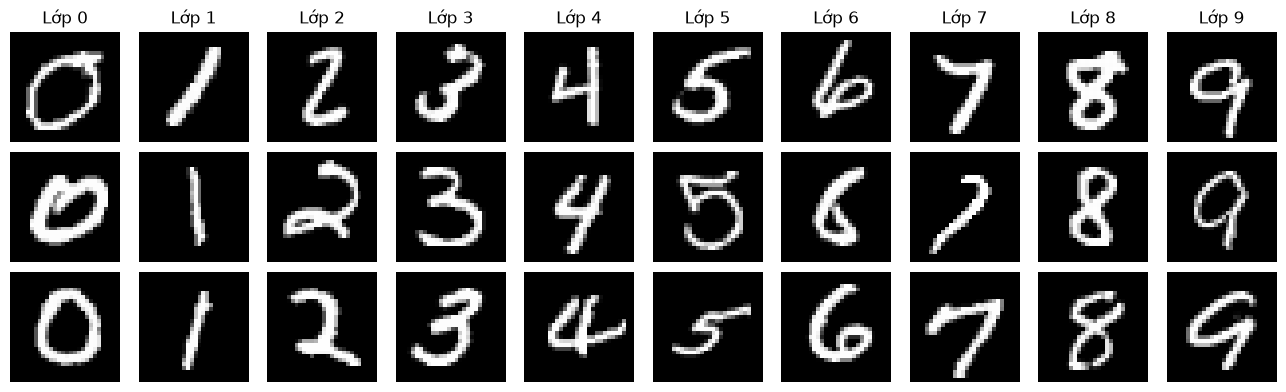

In [4]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 10, figsize=(13, 4))
for digit in range(10):
    indices = rng.choice(np.flatnonzero(y_train == digit), 3, replace=False)
    for row, idx in enumerate(indices):
        axes[row, digit].imshow(X_train[idx].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
        axes[row, digit].axis('off')
    axes[0, digit].set_title(f'Lớp {digit}')
fig.tight_layout()
fig.savefig(OUTPUT / 'digit_examples.png', dpi=300, bbox_inches='tight')
plt.show()


**Nhận xét:** nét viết có thể khác nhau về độ nghiêng, độ dày và hình dạng ngay trong một lớp. Các giả thuyết về chữ số dễ nhầm cần kiểm chứng bằng confusion matrix sau huấn luyện.


## 5. Độ thưa và ảnh trung bình

Độ thưa ở đây là tỷ lệ pixel **đúng bằng 0** trên mỗi ảnh, không phải kết quả phân đoạn nền bằng ngưỡng.


count    60000.0000
mean         0.8088
std          0.0529
min          0.5523
25%          0.7730
50%          0.8087
75%          0.8444
max          0.9566
Name: zero_pixel_ratio, dtype: float64

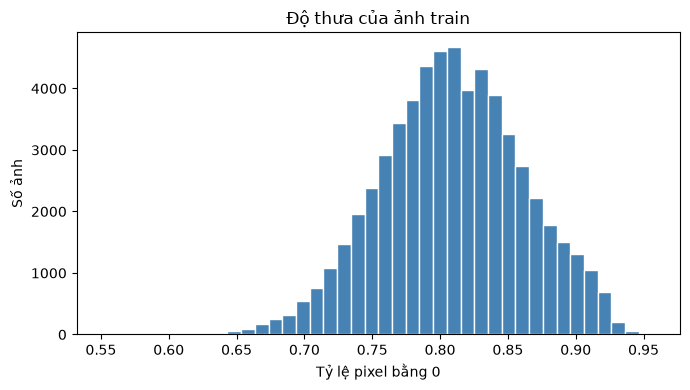

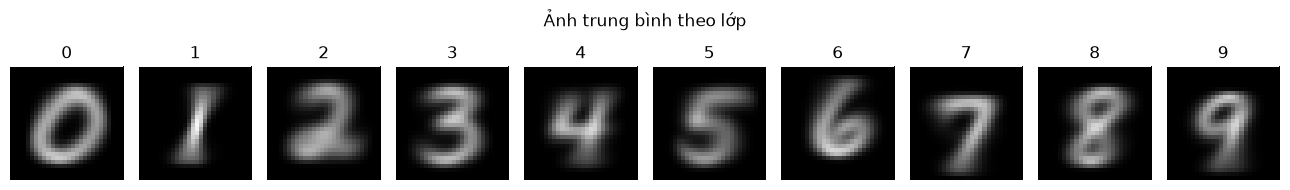

Trung vị tỷ lệ pixel bằng 0: 80.87%.
Số pixel không biến thiên trên train gốc: 67


In [5]:
zero_ratio = (X_train == 0).mean(axis=1)
zero_summary = pd.Series(zero_ratio, name='zero_pixel_ratio').describe()
display(zero_summary.round(4))
zero_summary.to_csv(OUTPUT / 'zero_pixel_summary.csv')

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(zero_ratio, bins=40, color='steelblue', edgecolor='white')
ax.set(xlabel='Tỷ lệ pixel bằng 0', ylabel='Số ảnh', title='Độ thưa của ảnh train')
fig.tight_layout()
fig.savefig(OUTPUT / 'zero_pixel_ratio.png', dpi=300)
plt.show()

means = np.stack([X_train[y_train == k].mean(axis=0) for k in range(10)])
fig, axes = plt.subplots(1, 10, figsize=(13, 2))
for digit, ax in enumerate(axes):
    ax.imshow(means[digit].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    ax.set_title(str(digit)); ax.axis('off')
fig.suptitle('Ảnh trung bình theo lớp')
fig.tight_layout()
fig.savefig(OUTPUT / 'class_mean_images.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Trung vị tỷ lệ pixel bằng 0: {np.median(zero_ratio):.2%}.')
print('Số pixel không biến thiên trên train gốc:', int((X_train.max(axis=0) == X_train.min(axis=0)).sum()))


**Nhận xét:** ảnh trung bình mô tả xu hướng nét chữ, không đại diện cho từng ảnh. Các pixel phương sai bằng 0 là lý do Gaussian NB cần làm trơn phương sai; notebook này chưa loại đặc trưng.


## 6. Kết luận

- Dùng chung đầu vào 784 đặc trưng, pixel chia 255 và nhãn nguyên cho các mô hình.
- Đánh giá bằng accuracy cùng các độ đo macro và confusion matrix.
- Chia 50.000 train / 10.000 validation bằng `test_size=10000, stratify=y, random_state=42`; giữ 10.000 test cho đánh giá cuối.
- Các hình EDA chỉ định hướng phân tích; kết luận về mô hình dựa trên thí nghiệm phân lớp.

Hình PNG 300 dpi và bảng CSV nằm trong `results/eda/`; chạy lại ghi đè file cùng tên.
